# CatBoost

CatBoost (Categorical Boosting) is an open-source gradient boosting algorithm developed by Yandex. It is based on decision trees and uses boosting to combine multiple weak learners into a strong predictive model.

CatBoost introduces techniques such as Ordered Boosting and specialized categorical feature processing to reduce prediction bias and improve model generalization.

Unlike traditional gradient boosting algorithms, CatBoost can handle categorical features directly without requiring extensive manual encoding.

## Types of CatBoost Models

1. **CatBoostRegressor:** Used for predicting continuous numerical values.
2. **CatBoostClassifier:** Used for classification problems involving categorical target variables.

## Key Features

- Ordered Boosting to help reduce prediction bias.
- Native handling of categorical features.
- Effective performance on structured and tabular datasets.
- Regularization techniques to reduce overfitting.
- Support for classification and regression tasks.

## Advantages

- Strong predictive performance on tabular datasets.
- Handles categorical variables efficiently.
- Requires relatively little preprocessing.
- Supports feature importance analysis.
- Offers several regularization and tuning options.

## Limitations

- Can be computationally expensive with large datasets.
- Training time may increase with many iterations.
- Hyperparameter tuning can require considerable resources.

## Applications

- Customer churn prediction.
- Credit risk assessment.
- Sales and demand forecasting.
- Fraud detection.
- Medical data classification.
- House price prediction.

In [32]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from catboost import CatBoostRegressor, CatBoostClassifier
from sklearn.datasets import fetch_california_housing, load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score,accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,classification_report,confusion_matrix,ConfusionMatrixDisplay,roc_curve)
import warnings
warnings.filterwarnings('ignore')

In [33]:
# load dataset
housing = fetch_california_housing(as_frame=True)

housing_df = housing.frame.copy()

print(housing_df.shape)
housing_df.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [34]:
housing_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [35]:
housing_df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [36]:
housing_df.isnull().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

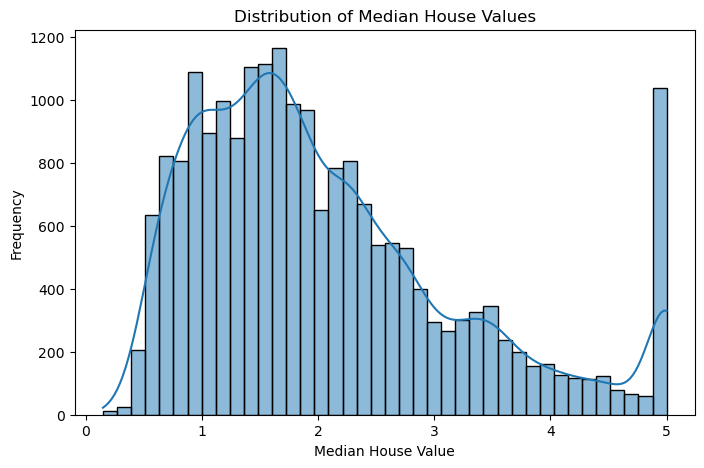

In [37]:
# target variable distribution
plt.figure(figsize=(8, 5))

sns.histplot(housing_df['MedHouseVal'],bins=40,kde=True)

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value")
plt.ylabel("Frequency")
plt.show()

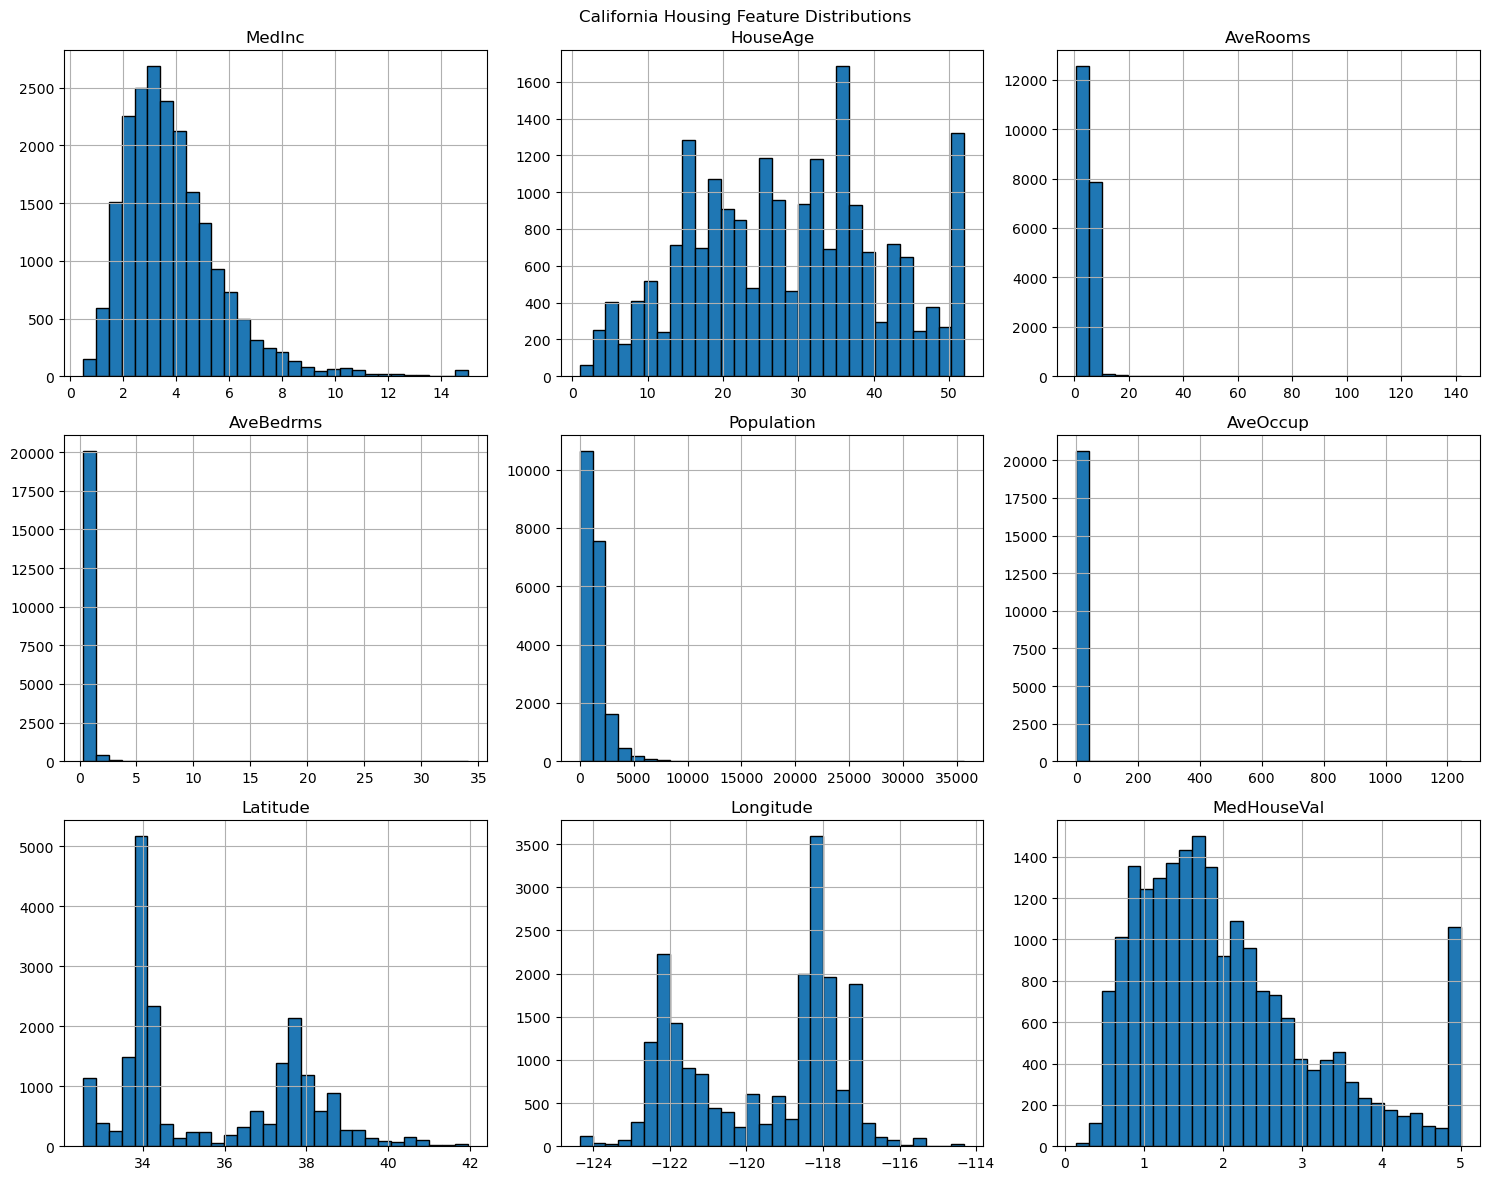

In [38]:
# feature distributions
housing_df.hist(figsize=(15, 12),bins=30,edgecolor='black')

plt.suptitle("California Housing Feature Distributions")
plt.tight_layout()
plt.show()

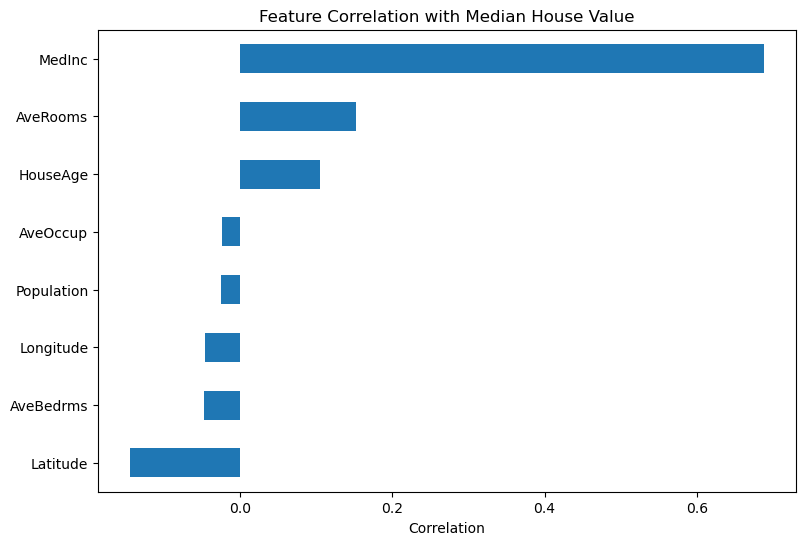

In [39]:
# feature rlship with target
target_corr = housing_df.corr()['MedHouseVal'].drop('MedHouseVal')

target_corr = target_corr.sort_values()

plt.figure(figsize=(9, 6))

target_corr.plot(kind='barh')

plt.title("Feature Correlation with Median House Value")
plt.xlabel("Correlation")
plt.show()

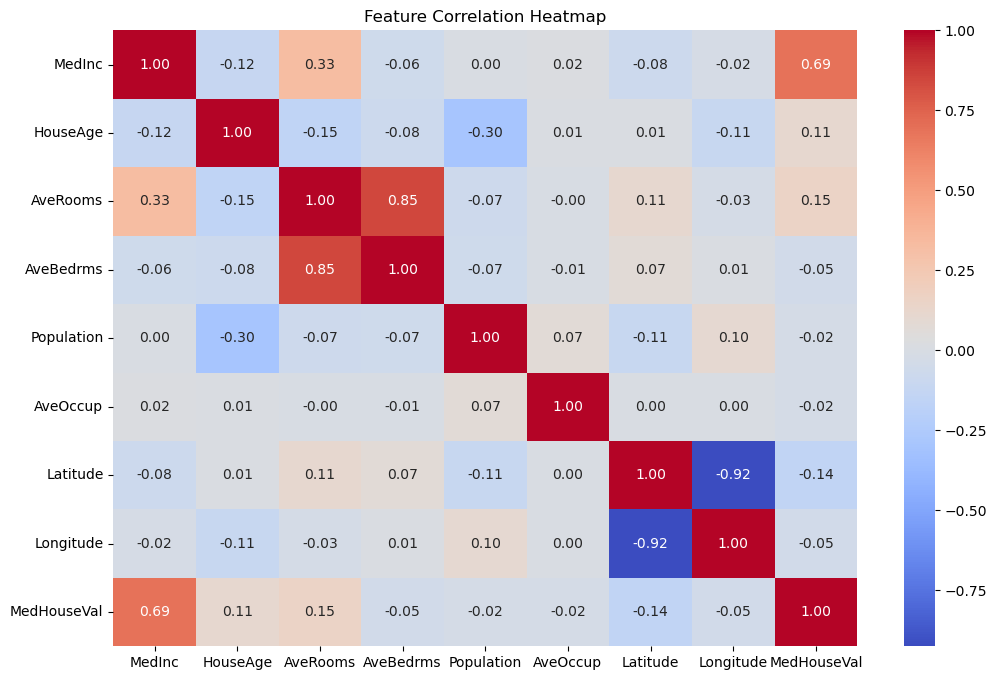

In [40]:
# correlation
plt.figure(figsize=(12, 8))

sns.heatmap(housing_df.corr(),annot=True,cmap='coolwarm',fmt='.2f')

plt.title("Feature Correlation Heatmap")
plt.show()

In [41]:
# Preprocessing
# separate features and targets
X = housing_df.drop('MedHouseVal', axis=1)
y = housing_df['MedHouseVal']

In [42]:
# train-test split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
print("Training Features:" ,X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (16512, 8)
Testing Features: (4128, 8)
Training Target: (16512,)
Testing Target: (4128,)


In [43]:
# Modelling
cat_reg = CatBoostRegressor(iterations=300,learning_rate=0.05,depth=6,loss_function='RMSE',random_seed=42,verbose=100,thread_count=2)

cat_reg.fit(X_train, y_train)

0:	learn: 1.1244518	total: 135ms	remaining: 40.2s
100:	learn: 0.5369823	total: 1.18s	remaining: 2.32s
200:	learn: 0.4900335	total: 2.15s	remaining: 1.06s
299:	learn: 0.4558204	total: 3.03s	remaining: 0us


CatBoostRegressor(depth=6, iterations=300, learning_rate=0.05, loss_function='RMSE', random_seed=42, thread_count=2, verbose=100)

In [44]:
# Predictions
y_train_pred = cat_reg.predict(X_train)
y_test_pred = cat_reg.predict(X_test)

In [45]:
# Evaluation
train_mae = mean_absolute_error(y_train, y_train_pred)
test_mae = mean_absolute_error(y_test, y_test_pred)

train_mse = mean_squared_error(y_train, y_train_pred)
test_mse = mean_squared_error(y_test, y_test_pred)

train_rmse = np.sqrt(train_mse)
test_rmse = np.sqrt(test_mse)

train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("Training MAE:", train_mae)
print("Testing MAE:", test_mae)

print("\nTraining MSE:", train_mse)
print("Testing MSE:", test_mse)

print("\nTraining RMSE:", train_rmse)
print("Testing RMSE:", test_rmse)

print("\nTraining R2:", train_r2)
print("Testing R2:", test_r2)

Training MAE: 0.31433541569345014
Testing MAE: 0.33220235014875954

Training MSE: 0.20777221779623944
Testing MSE: 0.2429642904299602

Training RMSE: 0.45582037887334464
Testing RMSE: 0.4929140801701248

Training R2: 0.8445724085238395
Testing R2: 0.8145889608020568


In [46]:
# Actual vs predicted
cat_results = pd.DataFrame({
    'Actual Values': y_test.values,
    'Predicted Values': y_test_pred
})

cat_results.head(10)

,Actual Values,Predicted Values
0,0.47700,0.534497
1,0.45800,1.116741
2,5.00001,4.572433
3,2.18600,2.473023
4,2.78000,2.376508
5,1.58700,1.623809
6,1.98200,2.355542
7,1.57500,1.612018
8,3.40000,2.932218
9,4.46600,4.620049


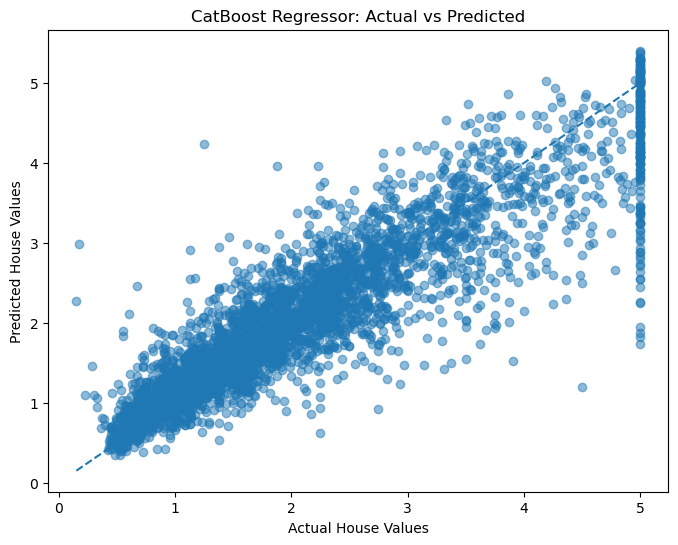

In [47]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_test_pred, alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")
plt.title("CatBoost Regressor: Actual vs Predicted")

plt.show()

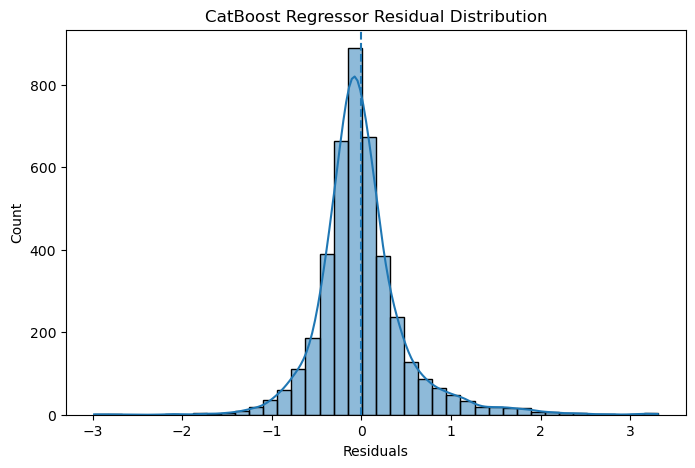

In [48]:
# Residual distribution
residuals = y_test - y_test_pred

plt.figure(figsize=(8, 5))

sns.histplot(residuals, bins=40, kde=True)

plt.axvline(0, linestyle='--')

plt.title("CatBoost Regressor Residual Distribution")
plt.xlabel("Residuals")
plt.show()

In [49]:
# feature importance
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': cat_reg.feature_importances_
}).sort_values(by='Importance', ascending=False)

feature_importance

,Feature,Importance
0,MedInc,36.079390
6,Latitude,21.159986
7,Longitude,18.447271
5,AveOccup,15.203773
1,HouseAge,4.814835
2,AveRooms,2.342279
3,AveBedrms,1.013285
4,Population,0.939182


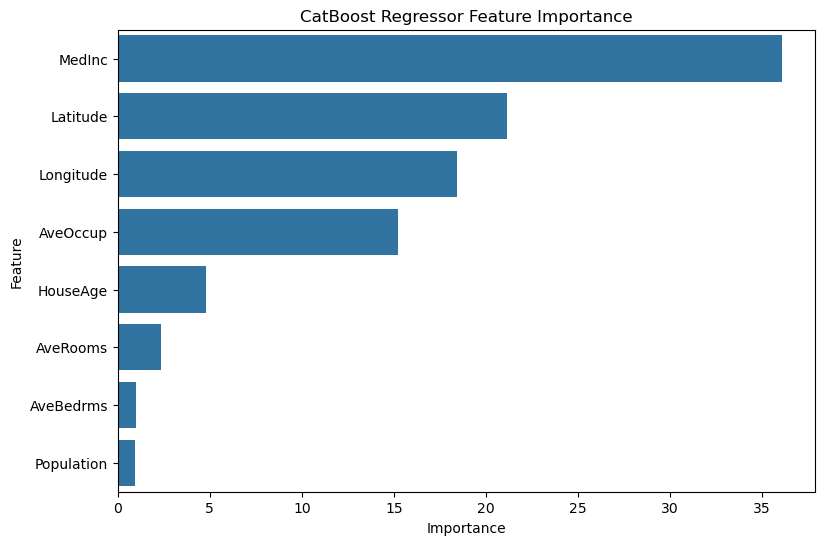

In [50]:
plt.figure(figsize=(9, 6))

sns.barplot(data=feature_importance,x='Importance',y='Feature')

plt.title("CatBoost Regressor Feature Importance")
plt.show()

In [51]:
# Hyperparameter tuning
cat_param_grid = {
    'iterations': [200, 300],
    'depth': [4, 6, 8],
    'learning_rate': [0.03, 0.05, 0.1],
    'l2_leaf_reg': [3, 5]
}
# GridSearch
cat_grid = GridSearchCV(
    estimator=CatBoostRegressor(loss_function='RMSE',random_seed=42,verbose=0,thread_count=2),param_grid=cat_param_grid,cv=3,scoring='neg_mean_squared_error',n_jobs=1,
    verbose=1
)
# fit gridsearch
cat_grid.fit(X_train, y_train)

Fitting 3 folds for each of 36 candidates, totalling 108 fits


,estimator,"CatBoostRegre...=2, verbose=0)"
,param_grid,"{'depth': [4, 6, ...], 'iterations': [200, 300], 'l2_leaf_reg': [3, 5], 'learning_rate': [0.03, 0.05, ...]}"
,scoring,'neg_mean_squared_error'
,n_jobs,1
,refit,True
,cv,3
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False


In [52]:
print("Best Parameters:", cat_grid.best_params_)
print("Best CV RMSE:", np.sqrt(-cat_grid.best_score_))

Best Parameters: {'depth': 8, 'iterations': 300, 'l2_leaf_reg': 3, 'learning_rate': 0.1}
Best CV RMSE: 0.46157917223191985


In [60]:
# tuned predictions
best_cat = cat_grid.best_estimator_

y_tuned_pred = best_cat.predict(X_test)
y_tuned_train_pred = best_cat.predict(X_train)

In [61]:
# tuned evaluation
tuned_mae = mean_absolute_error(y_test, y_tuned_pred)
tuned_mse = mean_squared_error(y_test, y_tuned_pred)
tuned_rmse = np.sqrt(tuned_mse)
tuned_r2 = r2_score(y_test, y_tuned_pred)

print("Tuned Training R2:", r2_score(y_train, y_tuned_train_pred))
print("Tuned Testing MAE:", tuned_mae)
print("Tuned Testing MSE:", tuned_mse)
print("Tuned Testing RMSE:", tuned_rmse)
print("Tuned Testing R2:", tuned_r2)

Tuned Training R2: 0.9052047015086324
Tuned Testing MAE: 0.3023266431971829
Tuned Testing MSE: 0.2065645250819717
Tuned Testing RMSE: 0.4544937019167281
Tuned Testing R2: 0.8423663691931773


In [62]:
# comparison
cat_comparison = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R2'],
    'Baseline': [test_mae,test_mse,test_rmse,test_r2
    ],
    'Tuned': [tuned_mae,tuned_mse,tuned_rmse,tuned_r2
    ]
})

cat_comparison

,Metric,Baseline,Tuned
0,MAE,0.332202,0.302327
1,MSE,0.242964,0.206565
2,RMSE,0.492914,0.454494
3,R2,0.814589,0.842366


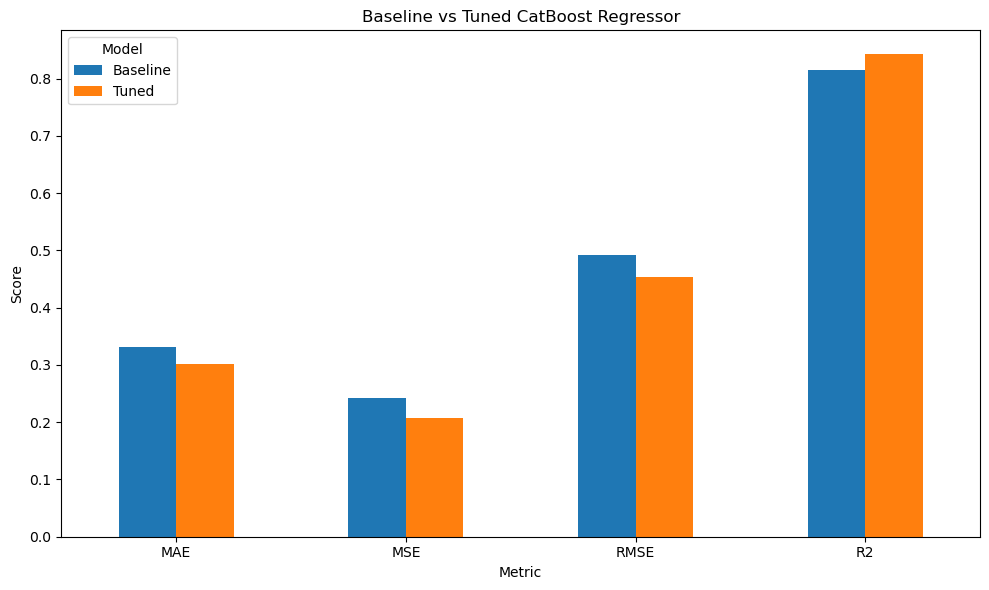

In [63]:
cat_comparison.set_index('Metric').plot(kind='bar',figsize=(10, 6))

plt.title("Baseline vs Tuned CatBoost Regressor")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(title="Model")
plt.tight_layout()
plt.show()

## Classification

In [64]:
# load dataset
cancer = load_breast_cancer()

cancer_df = pd.DataFrame(cancer.data,columns=cancer.feature_names)

cancer_df['target'] = cancer.target

print(cancer_df.shape)
cancer_df.head()

(569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [65]:
cancer_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [66]:
cancer_df.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


In [67]:
# missing values
cancer_df.isnull().sum()

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64

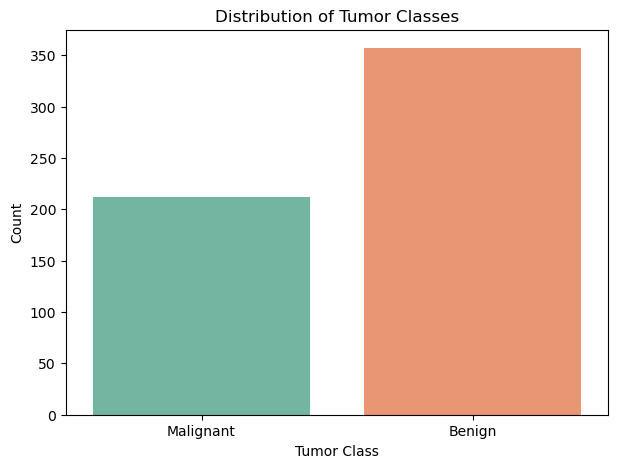

In [68]:
# target distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=cancer_df,x='target',hue='target',palette='Set2',legend=False)

plt.xticks([0, 1], ['Malignant', 'Benign'])
plt.title("Distribution of Tumor Classes")
plt.xlabel("Tumor Class")
plt.ylabel("Count")
plt.show()

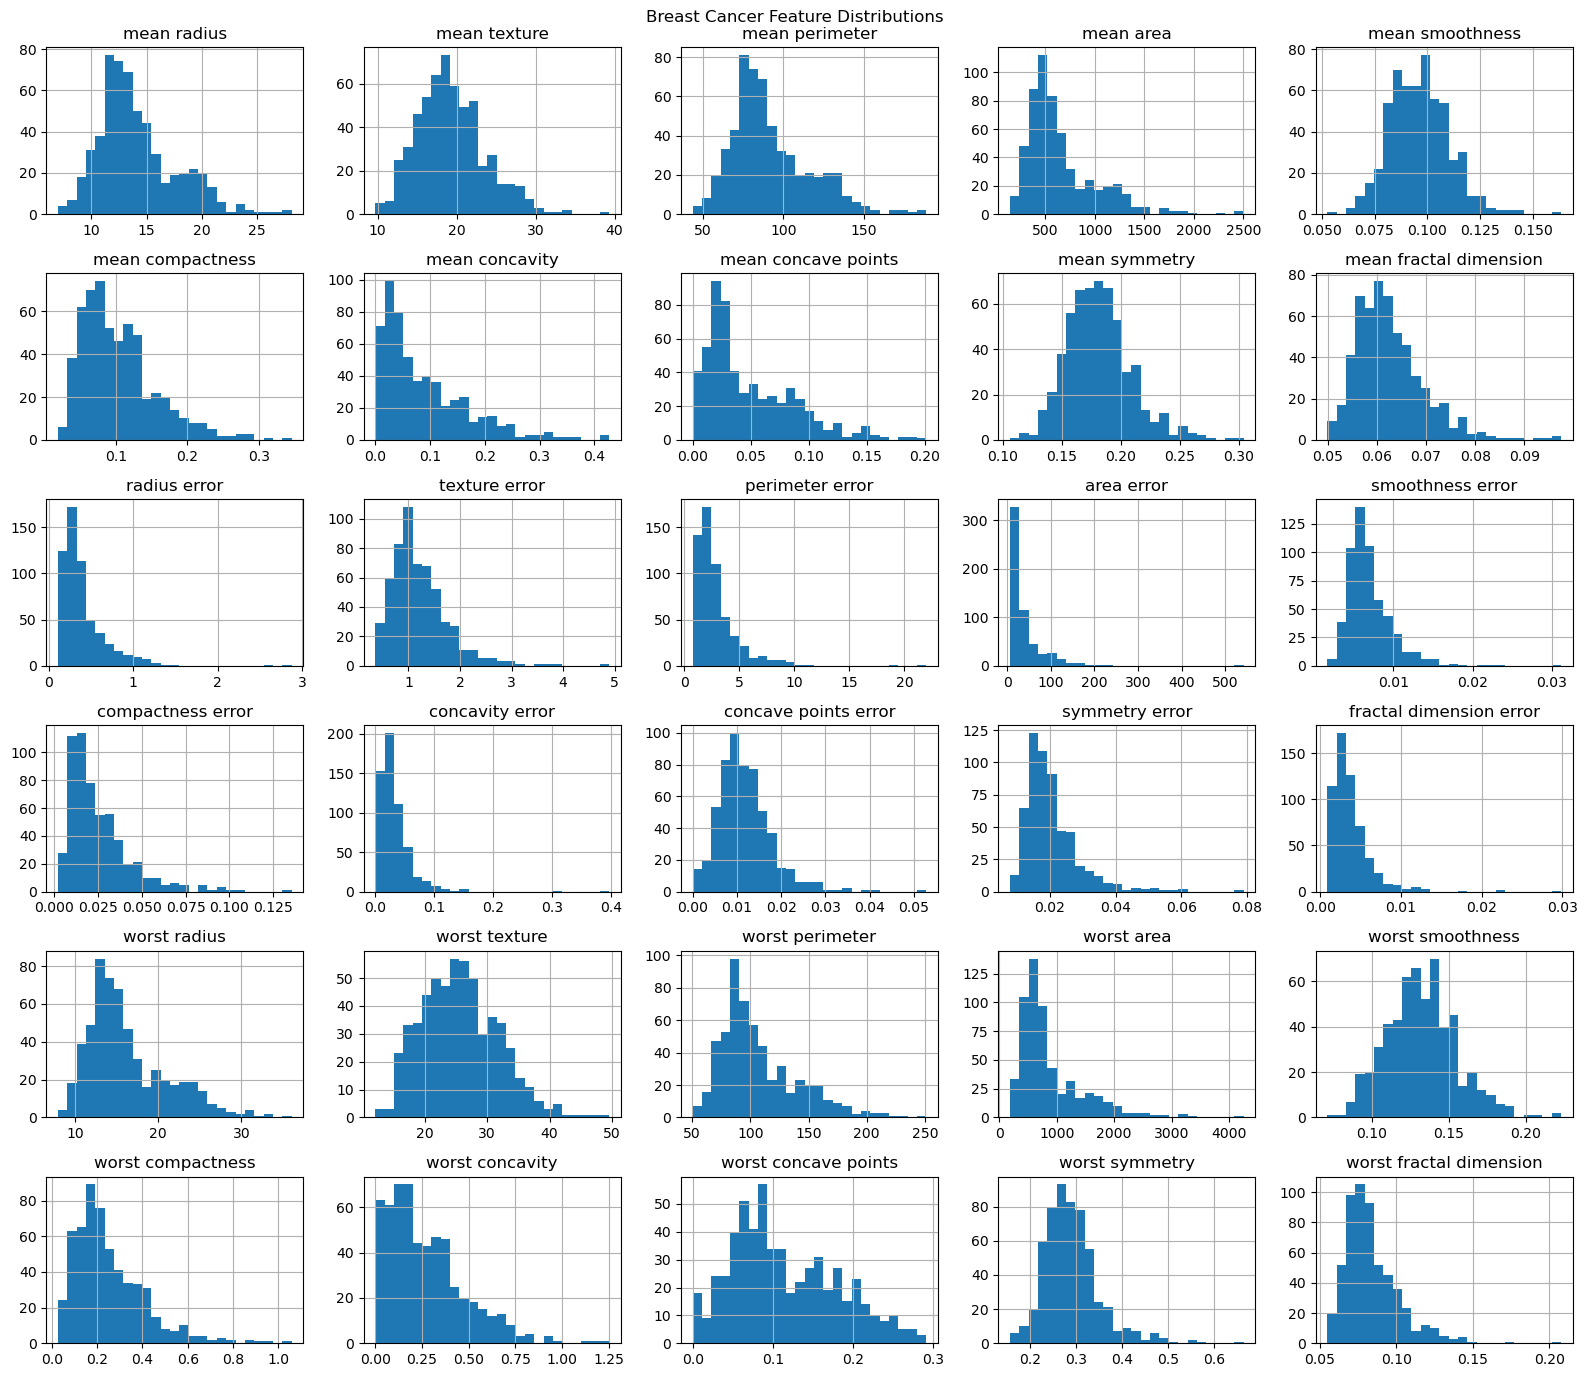

In [69]:
# feature distribution
cancer_df.drop('target', axis=1).hist(figsize=(16, 14),bins=25)

plt.suptitle("Breast Cancer Feature Distributions")
plt.tight_layout()
plt.show()

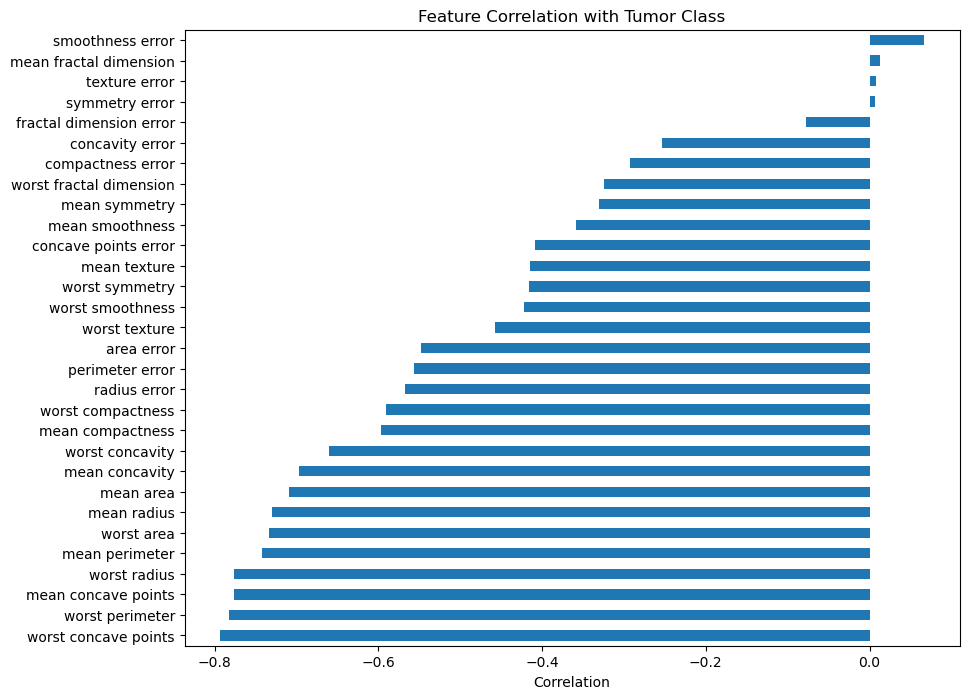

In [70]:
# feature correlation with target
target_corr = (cancer_df.corr()['target'].drop('target').sort_values())

plt.figure(figsize=(10, 8))

target_corr.plot(kind='barh')

plt.title("Feature Correlation with Tumor Class")
plt.xlabel("Correlation")
plt.show()

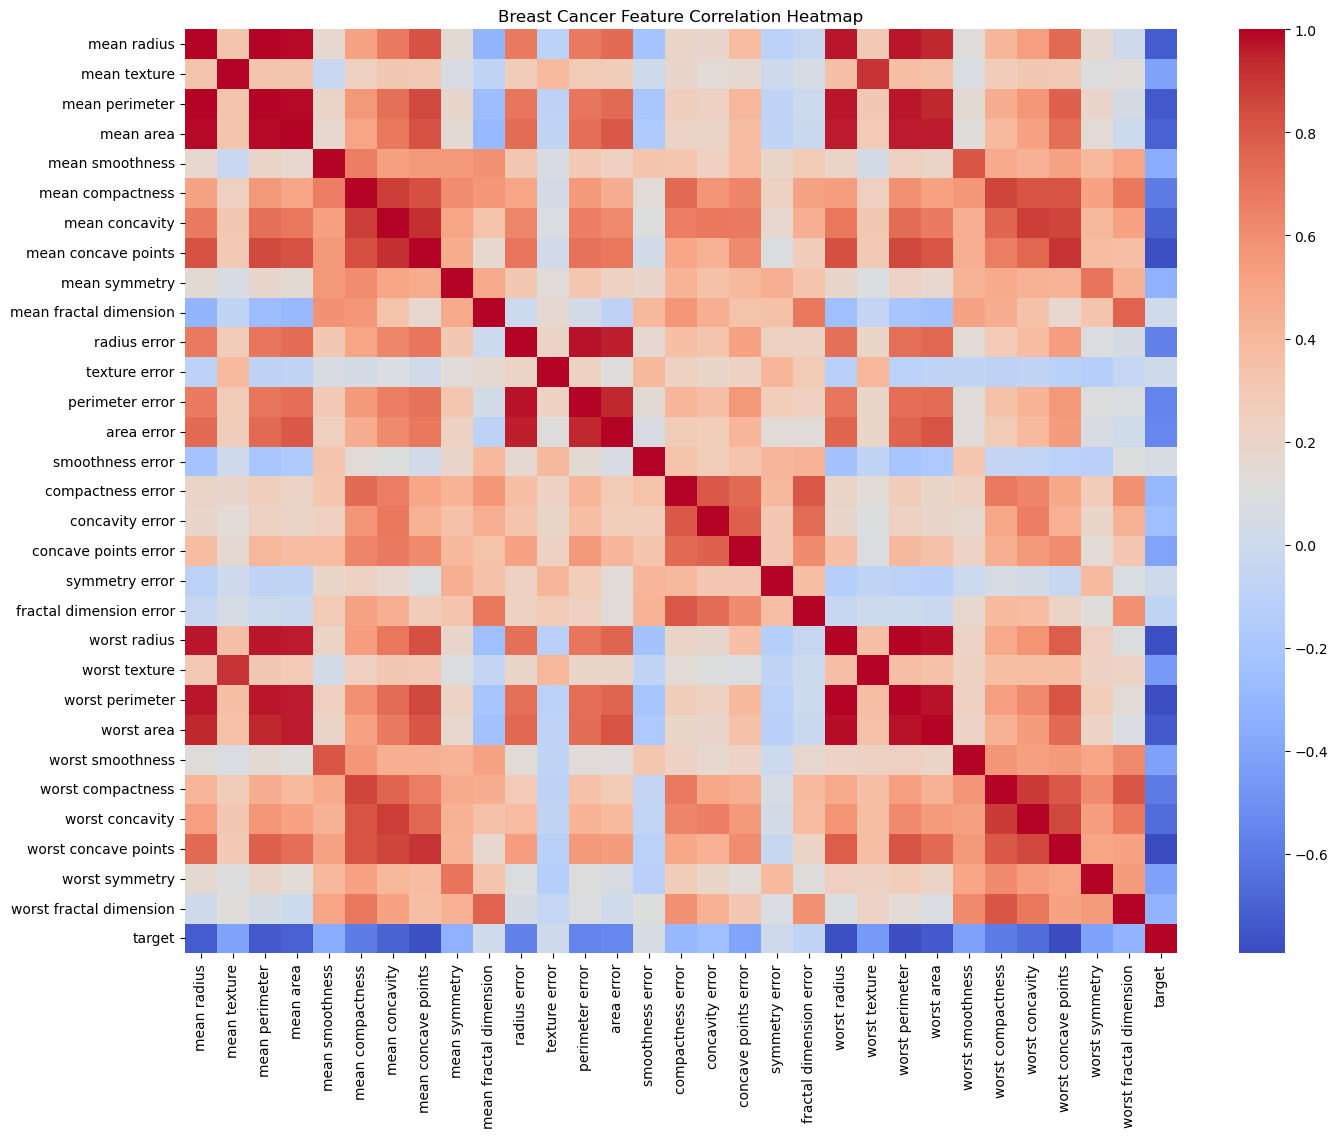

In [71]:
# correlation analysis
plt.figure(figsize=(16, 12))

sns.heatmap(cancer_df.corr(),cmap='coolwarm',annot=False)

plt.title("Breast Cancer Feature Correlation Heatmap")
plt.show()

In [72]:
# Preprocessing
# separate features and targets
X = cancer_df.drop('target', axis=1)
y = cancer_df['target']

In [73]:
# train-test split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

Training Features: (455, 30)
Testing Features: (114, 30)

Training Target: (455,)
Testing Target: (114,)

Training Class Distribution:
target
1    285
0    170
Name: count, dtype: int64

Testing Class Distribution:
target
1    72
0    42
Name: count, dtype: int64


In [74]:
# Modelling
cat_clf = CatBoostClassifier(iterations=300,learning_rate=0.05,depth=6,loss_function='Logloss',eval_metric='AUC',random_seed=42,verbose=100,thread_count=2)

cat_clf.fit(X_train, y_train)

0:	total: 40.2ms	remaining: 12s
100:	total: 1.75s	remaining: 3.45s
200:	total: 3.53s	remaining: 1.74s
299:	total: 5.18s	remaining: 0us


CatBoostClassifier(depth=6, eval_metric='AUC', iterations=300, learning_rate=0.05, loss_function='Logloss', random_seed=42, thread_count=2, verbose=100)

In [75]:
# predictions
y_train_pred = cat_clf.predict(X_train).flatten()
y_test_pred = cat_clf.predict(X_test).flatten()

y_test_proba = cat_clf.predict_proba(X_test)[:, 1]

In [76]:
# evaluation
cat_accuracy = accuracy_score(y_test, y_test_pred)
cat_precision = precision_score(y_test, y_test_pred)
cat_recall = recall_score(y_test, y_test_pred)
cat_f1 = f1_score(y_test, y_test_pred)
cat_roc_auc = roc_auc_score(y_test, y_test_proba)

print("Training Accuracy:", accuracy_score(y_train, y_train_pred))
print("Testing Accuracy:", cat_accuracy)

print("\nPrecision:", cat_precision)
print("Recall:", cat_recall)
print("F1 Score:", cat_f1)
print("ROC-AUC:", cat_roc_auc)

Training Accuracy: 1.0
Testing Accuracy: 0.956140350877193

Precision: 0.9466666666666667
Recall: 0.9861111111111112
F1 Score: 0.9659863945578231
ROC-AUC: 0.996031746031746


In [77]:
# classification report
print(classification_report(y_test,y_test_pred,target_names=['Malignant', 'Benign']))

              precision    recall  f1-score   support

   Malignant       0.97      0.90      0.94        42
      Benign       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



In [78]:
print("Malignant Precision:",
      precision_score(y_test, y_test_pred, pos_label=0))

print("Malignant Recall:",
      recall_score(y_test, y_test_pred, pos_label=0))

print("Malignant F1 Score:",
      f1_score(y_test, y_test_pred, pos_label=0))

Malignant Precision: 0.9743589743589743
Malignant Recall: 0.9047619047619048
Malignant F1 Score: 0.9382716049382716


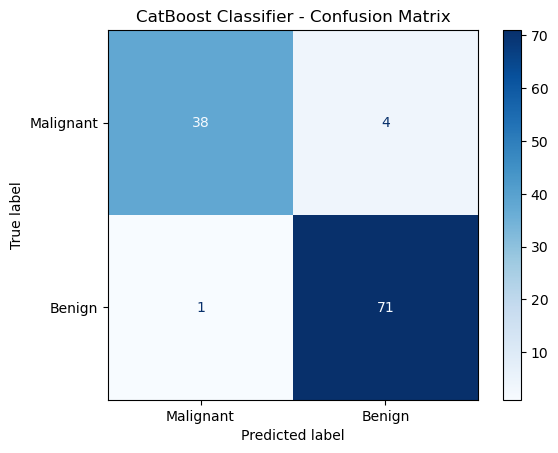

In [79]:
# confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test,y_test_pred,display_labels=['Malignant', 'Benign'],cmap='Blues')

plt.title("CatBoost Classifier - Confusion Matrix")
plt.show()

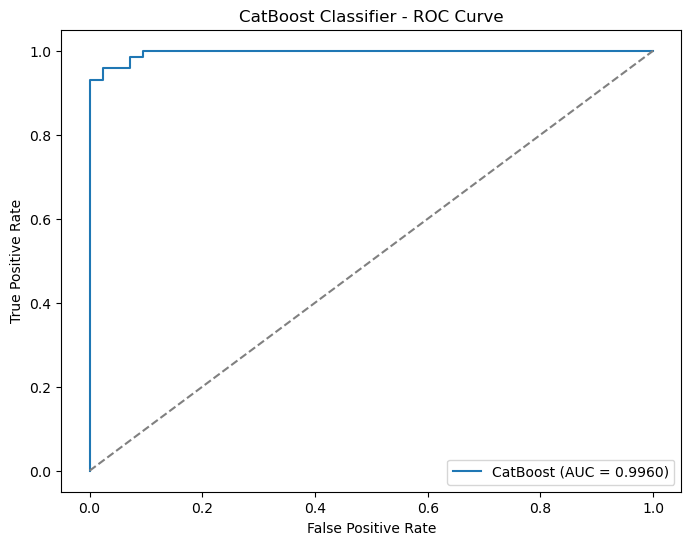

In [80]:
# ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)

plt.figure(figsize=(8, 6))

plt.plot(fpr,tpr,label=f'CatBoost (AUC = {cat_roc_auc:.4f})')

plt.plot([0, 1], [0, 1], linestyle='--', color='grey')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("CatBoost Classifier - ROC Curve")
plt.legend()
plt.show()

In [81]:
# feature importance
cat_feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': cat_clf.feature_importances_
}).sort_values(by='Importance', ascending=False)

cat_feature_importance.head(15)

,Feature,Importance
21,worst texture,11.106434
27,worst concave points,9.031952
23,worst area,8.430105
20,worst radius,6.976804
22,worst perimeter,6.904090
7,mean concave points,6.474935
1,mean texture,5.280099
24,worst smoothness,4.697047
13,area error,3.986116
6,mean concavity,2.801341


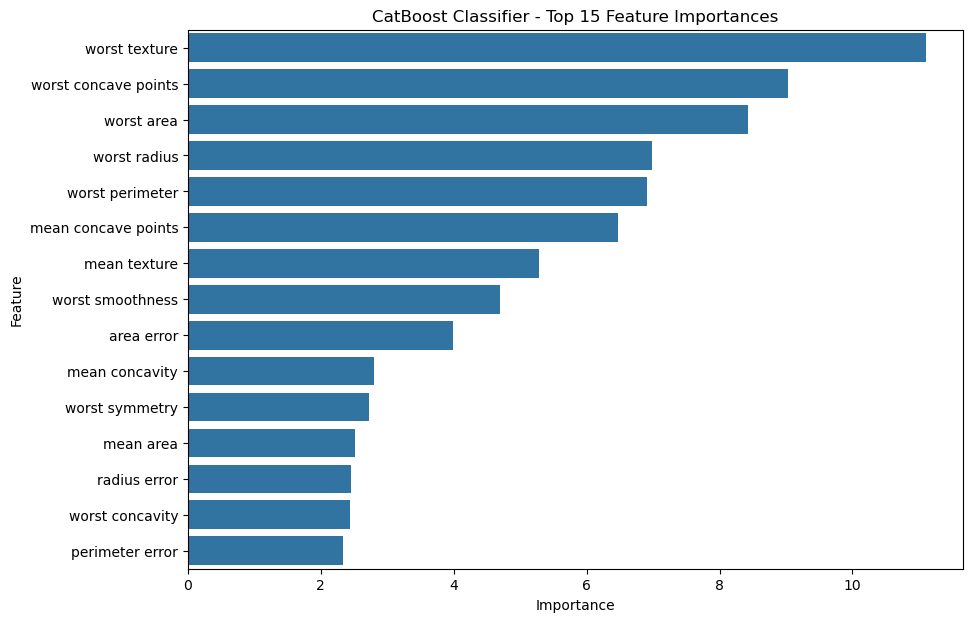

In [82]:
plt.figure(figsize=(10, 7))

sns.barplot(data=cat_feature_importance.head(15),x='Importance',y='Feature')

plt.title("CatBoost Classifier - Top 15 Feature Importances")
plt.show()

In [83]:
# Actual vs predicted
cat_results = pd.DataFrame({
    'Actual Category': y_test.values,
    'Predicted Category': y_test_pred
})

cat_results.head(10)

,Actual Category,Predicted Category
0,0,0
1,1,1
2,0,0
3,1,0
4,0,0
5,1,1
6,1,1
7,0,0
8,0,0
9,0,0


In [85]:
# Hyperparameter tuning
cat_clf_param_grid = {
    'iterations': [200, 300],
    'depth': [4, 6, 8],
    'learning_rate': [0.03, 0.05, 0.1],
    'l2_leaf_reg': [3, 5]
}
# Gridsearch cv
cat_clf_grid = GridSearchCV(estimator=CatBoostClassifier(loss_function='Logloss',eval_metric='AUC',random_seed=42,verbose=0,thread_count=2
    ),
    param_grid=cat_clf_param_grid,cv=5,scoring='roc_auc',n_jobs=1,verbose=1
)
# fit cv
cat_clf_grid.fit(X_train, y_train)

Fitting 5 folds for each of 36 candidates, totalling 180 fits


,estimator,"CatBoostClass...=2, verbose=0)"
,param_grid,"{'depth': [4, 6, ...], 'iterations': [200, 300], 'l2_leaf_reg': [3, 5], 'learning_rate': [0.03, 0.05, ...]}"
,scoring,'roc_auc'
,n_jobs,1
,refit,True
,cv,5
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False


In [86]:
print("Best Parameters:", cat_clf_grid.best_params_)
print("Best Cross-Validation ROC-AUC:", cat_clf_grid.best_score_)

Best Parameters: {'depth': 4, 'iterations': 200, 'l2_leaf_reg': 3, 'learning_rate': 0.1}
Best Cross-Validation ROC-AUC: 0.9928792569659443


In [87]:
# tuned model predictions
best_cat_clf = cat_clf_grid.best_estimator_

y_tuned_pred = best_cat_clf.predict(X_test).flatten()
y_tuned_proba = best_cat_clf.predict_proba(X_test)[:, 1]

y_tuned_train_pred = best_cat_clf.predict(X_train).flatten()

In [88]:
# tuned evaluation
tuned_accuracy = accuracy_score(y_test, y_tuned_pred)
tuned_precision = precision_score(y_test, y_tuned_pred)
tuned_recall = recall_score(y_test, y_tuned_pred)
tuned_f1 = f1_score(y_test, y_tuned_pred)
tuned_roc_auc = roc_auc_score(y_test, y_tuned_proba)

print("Tuned Training Accuracy:",accuracy_score(y_train, y_tuned_train_pred))
print("Tuned Testing Accuracy:", tuned_accuracy)
print("Precision:", tuned_precision)
print("Recall:", tuned_recall)
print("F1 Score:", tuned_f1)
print("ROC-AUC:", tuned_roc_auc)

Tuned Training Accuracy: 1.0
Tuned Testing Accuracy: 0.9473684210526315
Precision: 0.9459459459459459
Recall: 0.9722222222222222
F1 Score: 0.958904109589041
ROC-AUC: 0.9937169312169312


In [89]:
# classification report
print(classification_report(y_test,y_tuned_pred,target_names=['Malignant', 'Benign']))

              precision    recall  f1-score   support

   Malignant       0.95      0.90      0.93        42
      Benign       0.95      0.97      0.96        72

    accuracy                           0.95       114
   macro avg       0.95      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



In [90]:
print("Malignant Precision:",
      precision_score(y_test, y_tuned_pred, pos_label=0))

print("Malignant Recall:",
      recall_score(y_test, y_tuned_pred, pos_label=0))

print("Malignant F1 Score:",
      f1_score(y_test, y_tuned_pred, pos_label=0))

Malignant Precision: 0.95
Malignant Recall: 0.9047619047619048
Malignant F1 Score: 0.926829268292683


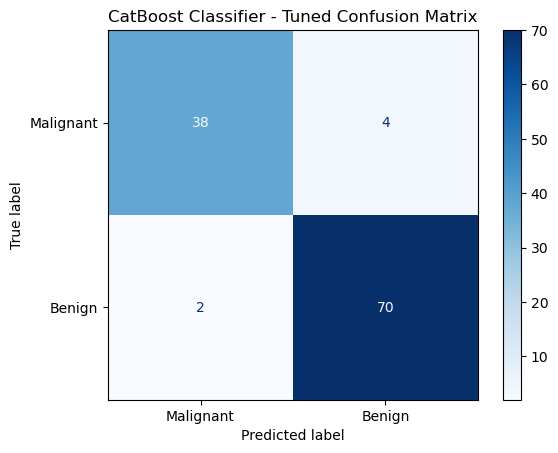

In [91]:
# tuned confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test,y_tuned_pred,display_labels=['Malignant', 'Benign'],cmap='Blues')

plt.title("CatBoost Classifier - Tuned Confusion Matrix")
plt.show()

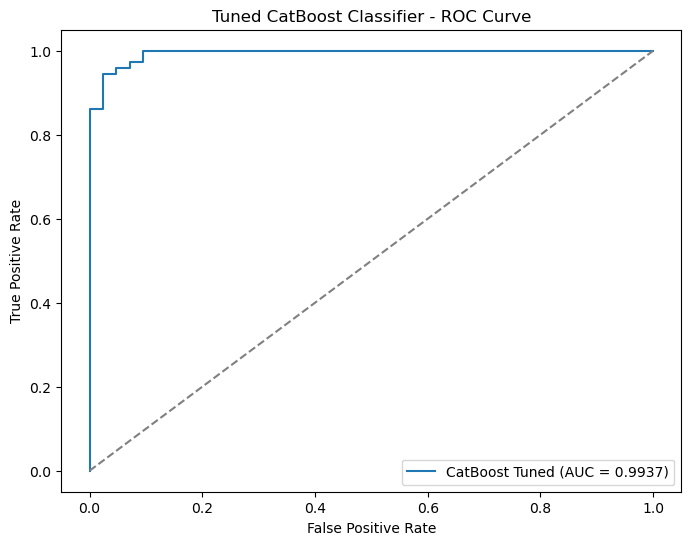

In [92]:
# tuned ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_tuned_proba)

plt.figure(figsize=(8, 6))

plt.plot(fpr,tpr,label=f'CatBoost Tuned (AUC = {tuned_roc_auc:.4f})')

plt.plot([0, 1], [0, 1], linestyle='--', color='grey')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Tuned CatBoost Classifier - ROC Curve")
plt.legend()
plt.show()

In [93]:
cat_clf_comparison = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1 Score',
        'ROC-AUC'
    ],
    'Baseline': [
        cat_accuracy,
        cat_precision,
        cat_recall,
        cat_f1,
        cat_roc_auc
    ],
    'Tuned': [
        tuned_accuracy,
        tuned_precision,
        tuned_recall,
        tuned_f1,
        tuned_roc_auc
    ]
})

cat_clf_comparison

,Metric,Baseline,Tuned
0,Accuracy,0.956140,0.947368
1,Precision,0.946667,0.945946
2,Recall,0.986111,0.972222
3,F1 Score,0.965986,0.958904
4,ROC-AUC,0.996032,0.993717


In [95]:
malignant_comparison = pd.DataFrame({
    'Model': ['Baseline', 'Tuned'],
    'Malignant Recall': [
        recall_score(y_test, y_test_pred, pos_label=0),
        recall_score(y_test, y_tuned_pred, pos_label=0)
    ]
})

malignant_comparison

,Model,Malignant Recall
0,Baseline,0.904762
1,Tuned,0.904762


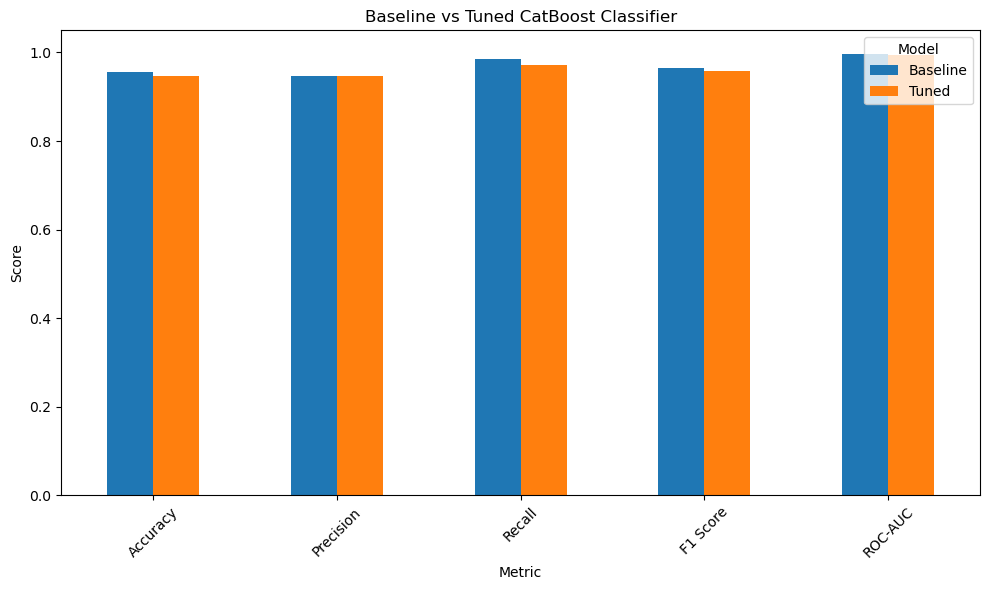

In [94]:
cat_clf_comparison.set_index('Metric').plot(kind='bar',figsize=(10, 6))

plt.title("Baseline vs Tuned CatBoost Classifier")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=45)
plt.legend(title="Model")
plt.tight_layout()
plt.show()

## Conclusion

The CatBoost Classifier was implemented using the Breast Cancer Wisconsin dataset to classify tumors as malignant or benign.

The baseline model was evaluated using accuracy, precision, recall, F1-score, and ROC-AUC.

Hyperparameter tuning was performed using GridSearchCV with five-fold cross-validation to identify an improved model configuration.

The baseline and tuned models were compared to assess their classification performance and generalization.

Malignant-class recall was also examined to understand how effectively the model identifies malignant cases.

CatBoost demonstrates the effectiveness of gradient boosting through sequential tree learning, ordered boosting, and regularization.

The dataset is used for educational machine-learning practice. The model is not intended for clinical diagnosis.